# Aula 7 — Algoritmos de regressão para previsão de variáveis industriais  
## Versão do professor

**Capacidades**
- Implementar algoritmos supervisionados e não supervisionados
- Organizar o ambiente de trabalho e as atividades
- Demonstrar atenção a detalhes

**Conhecimentos**
- Regressão
- Linear
- Não linear (ex.: polinomial)
- Logística
- Biblioteca Python
- Scikit-learn

**Objetivo da aula**  
Implementar modelos de regressão para prever uma variável contínua do processo industrial, comparando o comportamento de um modelo linear e de um modelo não linear.

**Variável-alvo deste notebook**  
`vazao_real_l_min`

**Arquivo utilizado**  
`dados_aula7_regressao_industrial.csv`

## 1. Contexto do problema

Neste estudo, o aluno atuará como analista de dados de uma planta química.  
O desafio é prever a **vazão real da linha** com base em variáveis operacionais do processo, como pressão, temperatura, abertura de válvula, vibração, pH, consumo de energia e características do produto.

A proposta desta aula é mostrar, passo a passo, como:

1. carregar a base de dados;
2. entender quais variáveis serão usadas;
3. tratar a base para o treinamento;
4. separar os dados em treino e validação;
5. criar modelos preditivos;
6. treinar os modelos;
7. gerar predições;
8. comparar métricas;
9. interpretar qual modelo se ajustou melhor ao problema.


In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

## 2. Carregamento da base

Nesta etapa, carregamos o arquivo CSV e verificamos:
- quantidade de linhas e colunas;
- nomes das variáveis;
- primeiras linhas da base;
- tipo de problema.

Como a variável-alvo é numérica contínua (`vazao_real_l_min`), estamos diante de um **problema de regressão**.

In [4]:
df = pd.read_csv("/content/dados_aula7_regressao_industrial.csv")

print("Dimensão da base:", df.shape)
display(df.head())
print("\nColunas:")
print(df.columns.tolist())

Dimensão da base: (266, 15)


,linha_producao,turno,produto_quimico,tipo_valvula,pressao_linha_bar,temperatura_produto_c,abertura_valvula_pct,vibracao_bomba_mm_s,ph_produto,consumo_energia_kwh,horas_operacao_bomba,particulas_ppm,viscosidade_cP,falha_operacional,vazao_real_l_min
0,Linha_B,Noite,Reagente_Y,Borboleta,7.20,29.54,41.56,3.90,6.71,122.07,1561,21.36,55.49,0,27.52
1,Linha_C,Tarde,Solvente_X,Borboleta,5.30,50.43,52.92,2.21,5.82,128.13,1501,19.75,48.70,0,36.80
2,Linha_B,Noite,Solvente_X,Globo,3.95,55.37,73.58,1.94,6.03,134.24,1188,21.45,15.00,0,45.95
3,Linha_B,Tarde,Aditivo_Z,Esfera,4.81,40.37,71.75,3.38,6.71,120.44,2095,13.30,48.18,0,49.50
4,Linha_A,Noite,Solvente_X,Borboleta,5.95,40.51,NaN,NaN,6.59,128.15,2003,11.58,55.20,0,46.66



Colunas:
['linha_producao', 'turno', 'produto_quimico', 'tipo_valvula', 'pressao_linha_bar', 'temperatura_produto_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'ph_produto', 'consumo_energia_kwh', 'horas_operacao_bomba', 'particulas_ppm', 'viscosidade_cP', 'falha_operacional', 'vazao_real_l_min']


## 3. Inspeção inicial da base

Antes de treinar qualquer modelo, é importante verificar:
- se há valores faltantes;
- se existem colunas categóricas;
- se a variável-alvo está correta;
- se o conjunto precisa de tratamento básico antes da modelagem.

Essa etapa evita erros no treinamento e melhora a organização do experimento.

In [5]:
print("Valores faltantes por coluna:")
display(df.isna().sum().sort_values(ascending=False))

print("\nTipos de dados:")
display(df.dtypes)

Valores faltantes por coluna:


,0
abertura_valvula_pct,7
vibracao_bomba_mm_s,7
pressao_linha_bar,6
temperatura_produto_c,6
produto_quimico,5
turno,0
linha_producao,0
tipo_valvula,0
ph_produto,0
consumo_energia_kwh,0



Tipos de dados:


,0
linha_producao,object
turno,object
produto_quimico,object
tipo_valvula,object
pressao_linha_bar,float64
temperatura_produto_c,float64
abertura_valvula_pct,float64
vibracao_bomba_mm_s,float64
ph_produto,float64
consumo_energia_kwh,float64


## 4. Definição das variáveis preditoras e da variável-alvo

Aqui separamos a base em:

- **X**: conjunto de variáveis de entrada (features);
- **y**: variável-alvo que o modelo tentará prever.

Neste exemplo:

- `X` = todas as colunas, exceto `vazao_real_l_min`;
- `y` = `vazao_real_l_min`.

Essa separação é essencial, pois o algoritmo precisa saber quais informações serão usadas para aprender e qual resultado ele deve tentar estimar.

In [6]:
X = df.drop(columns=["vazao_real_l_min"])
y = df["vazao_real_l_min"]

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)
display(X.head())
display(y.head())

Dimensão de X: (266, 14)
Dimensão de y: (266,)


,linha_producao,turno,produto_quimico,tipo_valvula,pressao_linha_bar,temperatura_produto_c,abertura_valvula_pct,vibracao_bomba_mm_s,ph_produto,consumo_energia_kwh,horas_operacao_bomba,particulas_ppm,viscosidade_cP,falha_operacional
0,Linha_B,Noite,Reagente_Y,Borboleta,7.20,29.54,41.56,3.90,6.71,122.07,1561,21.36,55.49,0
1,Linha_C,Tarde,Solvente_X,Borboleta,5.30,50.43,52.92,2.21,5.82,128.13,1501,19.75,48.70,0
2,Linha_B,Noite,Solvente_X,Globo,3.95,55.37,73.58,1.94,6.03,134.24,1188,21.45,15.00,0
3,Linha_B,Tarde,Aditivo_Z,Esfera,4.81,40.37,71.75,3.38,6.71,120.44,2095,13.30,48.18,0
4,Linha_A,Noite,Solvente_X,Borboleta,5.95,40.51,NaN,NaN,6.59,128.15,2003,11.58,55.20,0


,vazao_real_l_min
0,27.52
1,36.80
2,45.95
3,49.50
4,46.66


## 5. Identificação das colunas numéricas e categóricas

Os algoritmos do scikit-learn normalmente exigem que:
- colunas categóricas sejam transformadas em formato numérico;
- valores faltantes sejam tratados;
- variáveis numéricas possam ser padronizadas quando necessário.

Por isso, vamos identificar quais colunas são:
- **numéricas**
- **categóricas**

In [7]:
colunas_numericas = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
colunas_categoricas = X.select_dtypes(include=["object"]).columns.tolist()

print("Colunas numéricas:")
print(colunas_numericas)

print("\nColunas categóricas:")
print(colunas_categoricas)

Colunas numéricas:
['pressao_linha_bar', 'temperatura_produto_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'ph_produto', 'consumo_energia_kwh', 'horas_operacao_bomba', 'particulas_ppm', 'viscosidade_cP', 'falha_operacional']

Colunas categóricas:
['linha_producao', 'turno', 'produto_quimico', 'tipo_valvula']


## 6. Preparação dos dados antes do treino

Em vez de tratar os dados manualmente fora do modelo, vamos construir um **pipeline**.

### O que esse pipeline fará?
Para colunas numéricas:
- preencher valores faltantes com a mediana;
- aplicar padronização com `StandardScaler`.

Para colunas categóricas:
- preencher valores faltantes com a categoria mais frequente;
- transformar categorias em variáveis numéricas com `OneHotEncoder`.

Isso garante:
- reprodutibilidade;
- organização do experimento;
- aplicação do mesmo tratamento em treino e validação.

In [8]:
transformador_numerico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessador = ColumnTransformer(transformers=[
    ("num", transformador_numerico, colunas_numericas),
    ("cat", transformador_categorico, colunas_categoricas)
])

preprocessador

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['pressao_linha_bar', 'temperatura_produto_c',
                                  'abertura_valvula_pct', 'vibracao_bomba_mm_s',
                                  'ph_produto', 'consumo_energia_kwh',
                                  'horas_operacao_bomba', 'particulas_ppm',
                                  'viscosidade_cP', 'falha_operacional']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['linha_producao', 'turno', 'produto_quimico',
                                  'tipo_valvula'])])

# Explicação:

## **Pipeline de pré-processamento de dados**

O objetivo dele é preparar automaticamente os dados antes do treinamento do modelo de Machine Learning.

---

## **Parte Numérica (`num`)**

Para colunas numéricas o sistema faz:

## **1. SimpleImputer**

Preenche valores ausentes utilizando:

* mediana (`median`)

---

## **2. StandardScaler**

Padroniza os números para deixar os valores na mesma escala.

Isso ajuda o algoritmo a aprender melhor.

---

## **Parte Categórica (`cat`)**

Para colunas de texto o sistema faz:

## **1. SimpleImputer**

Preenche valores ausentes utilizando:

* valor mais frequente (`most_frequent`)

---

## **2. OneHotEncoder**

Transforma categorias em números utilizando:

* One-Hot Encoding

Exemplo:

* Solda
* Pintura
* Usinagem

viram colunas numéricas.

---

## **ColumnTransformer**

O `ColumnTransformer` organiza tudo automaticamente:

* aplica um tratamento para números
* aplica outro tratamento para categorias

---

## **Ideia principal do resultado**

A imagem mostra que:

> o Pipeline automatiza toda a preparação dos dados antes do treinamento do modelo.


## 7. Separação dos dados em treino e validação

### O que significa separar treino e validação?
Essa é uma das etapas mais importantes da modelagem.

- **Treino**: parte da base usada para o modelo aprender padrões.
- **Validação (teste, neste exemplo)**: parte da base reservada para verificar como o modelo se comporta em dados que ele ainda não viu.

### Por que isso é importante?
Se treinarmos e avaliarmos no mesmo conjunto de dados, o resultado pode parecer artificialmente bom.  
Separar os dados ajuda a medir a capacidade de generalização do modelo.

### Parâmetros usados
- `test_size=0.2` → 20% da base será usada para validação;
- `random_state=42` → garante reprodutibilidade;
- 80% fica para treino e 20% para validação.

In [9]:
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_treino:", X_treino.shape)
print("X_validacao:", X_validacao.shape)
print("y_treino:", y_treino.shape)
print("y_validacao:", y_validacao.shape)

X_treino: (212, 14)
X_validacao: (54, 14)
y_treino: (212,)
y_validacao: (54,)


## Explicação:

utilizando o `train_test_split()`.

---

# **O que aconteceu**

O conjunto de dados foi dividido em:

* 80% para treino
* 20% para validação

porque foi utilizado:

```python id="kzd6xg"
test_size=0.2
```

---

# **Resultados**

## `X_treino: (212, 14)`

* 212 linhas de treino
* 14 colunas de características

Esses dados serão usados para ensinar o modelo.

---

## `X_validacao: (54, 14)`

* 54 linhas para teste/validação
* mesmas 14 características

Esses dados verificam se o modelo realmente aprendeu.

---

## `y_treino: (212,)`

Contém:

* as respostas corretas do treino

para as 212 amostras.

---

## `y_validacao: (54,)`

Contém:

* as respostas corretas da validação

para as 54 amostras.

---

> os dados foram separados entre aprendizado e validação para testar o desempenho do modelo de forma confiável.


## 8. Criação do primeiro modelo preditivo — Regressão Linear

Agora vamos criar o primeiro modelo.

### O que é a regressão linear?
É um algoritmo que tenta explicar a variável-alvo por meio de uma relação linear entre as variáveis de entrada e a saída.

### Estrutura adotada
Vamos juntar:
1. **pré-processamento**
2. **modelo**

Tudo dentro de um único pipeline.
Isso evita inconsistências e torna o fluxo mais profissional.

In [10]:
modelo_linear = Pipeline(steps=[
    ("preprocessamento", preprocessador),
    ("modelo", LinearRegression())
])

modelo_linear

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['pressao_linha_bar',
                                                   'temperatura_produto_c',
                                                   'abertura_valvula_pct',
                                                   'vibracao_bomba_mm_s',
                                                   'ph_produto',
                                                   'consumo_energia_kwh',
                                                   'horas_operacao_bomba',
                                                   'particulas_ppm',
                                                   'viscosidade_cP',
                                                   'falha_operacional']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['linha_producao', 'turno',
                                                   'produto_quimico',
                                                   'tipo_valvula'])])),
                ('modelo', LinearRegression())])

#Explicação:

# **Pipeline completo de Machine Learning**

Ele automatiza:

* o pré-processamento dos dados
* e o treinamento do modelo de regressão linear.

---

# **Etapa de Pré-processamento**

O `ColumnTransformer` separa os dados em:

## **Dados Numéricos (`num`)**

O sistema:

* preenche valores ausentes (`SimpleImputer`)
* padroniza os valores (`StandardScaler`)

---

## **Dados Categóricos (`cat`)**

O sistema:

* preenche valores ausentes
* transforma categorias em números (`OneHotEncoder`)

---

# **Modelo Final**

Depois do tratamento dos dados:

o `LinearRegression()` recebe os dados preparados para aprender os padrões da regressão.

---
> o Pipeline automatiza toda a preparação dos dados e conecta diretamente ao modelo de Machine Learning, deixando o processo mais organizado e confiável.


## 9. Treinamento do modelo linear

### O que significa treinar o modelo?
Treinar significa fazer o algoritmo aprender, a partir dos dados de treino, a relação entre as variáveis preditoras (`X_treino`) e a variável-alvo (`y_treino`).

Nesta etapa, o modelo observa exemplos históricos e ajusta seus parâmetros internos para produzir previsões.

In [11]:
modelo_linear.fit(X_treino, y_treino)
print("Modelo linear treinado com sucesso.")

Modelo linear treinado com sucesso.


## 10. Predição com o modelo linear

Depois do treinamento, usamos os dados de validação para gerar previsões.

### O que acontece aqui?
O modelo recebe `X_validacao` e tenta estimar os valores de `vazao_real_l_min`.

Essas estimativas serão comparadas com os valores reais de `y_validacao`.

In [12]:
pred_linear = modelo_linear.predict(X_validacao)

resultado_linear = pd.DataFrame({
    "valor_real": y_validacao.values,
    "predicao_linear": pred_linear
})

display(resultado_linear.head())


,valor_real,predicao_linear
0,34.19,31.613671
1,34.49,34.909643
2,25.94,17.411885
3,47.04,43.961261
4,38.92,41.792494


# Explicação:

# **Regressão Linear**

---

# **O que aconteceu**

O modelo utilizou:

```python id="eq7g0w"
modelo_linear.predict(X_validacao)
```
para prever valores numéricos utilizando os dados de validação.
---

# **Tabela apresentada**

A tabela compara:

* `valor_real`
* `predicao_linear`
---

# **Exemplo**

| Valor real | Predição |
| ---------- | -------- |
| 34.19      | 31.61    |

Isso significa que:

* o valor verdadeiro era `34.19`
* o modelo previu `31.61`
---

# **Objetivo dessa comparação**

Verificar:

* o quanto o modelo consegue se aproximar dos valores reais.

Quanto mais próximos:

* melhor o desempenho da regressão.

---
> o modelo de regressão linear está tentando prever valores contínuos e comparar suas previsões com os dados reais para medir sua precisão.


## 11. Métricas do modelo linear

Agora vamos avaliar o desempenho do modelo.

### Métricas utilizadas
- **MAE**: erro absoluto médio. Mede o erro médio em unidades da variável.
- **RMSE**: raiz do erro quadrático médio. Penaliza mais erros grandes.
- **R²**: indica quanto da variação da variável-alvo foi explicada pelo modelo.

### Como interpretar?
- **MAE menor** → melhor;
- **RMSE menor** → melhor;
- **R² maior** → melhor.

In [13]:
mae_linear = mean_absolute_error(y_validacao, pred_linear)
rmse_linear = mean_squared_error(y_validacao, pred_linear)
r2_linear = r2_score(y_validacao, pred_linear)

print("Métricas - Regressão Linear")
print(f"MAE : {mae_linear:.4f}")
print(f"RMSE: {rmse_linear:.4f}")
print(f"R²  : {r2_linear:.4f}")

Métricas - Regressão Linear
MAE : 2.9592
RMSE: 14.5833
R²  : 0.7368


# Explicação:

# **Regressão Linear**

Foram calculadas três métricas principais:

---

# **MAE (Erro Médio Absoluto)**

```txt id="e3t9mx"
MAE: 2.9592
```

Mostra o erro médio das previsões.

Isso significa que:

* o modelo erra aproximadamente `2.95` unidades em média.

Quanto menor:

* melhor.

---

# **RMSE**

```txt id="hgm9qu"
RMSE: 14.5833
```

Mede o tamanho dos erros dando mais peso para erros grandes.

> o RMSE fica na mesma unidade da variável-alvo, portanto: <br/>
> Se a vazão real for: <br/>
> 50 L/min </br>
> O modelo pode produzir previsões como: <br/>
> * 36 L/min
> * 64 L/min
> * 47 L/min

Quanto menor:

* melhor o ajuste do modelo.

---

# **R² (Coeficiente de Determinação)**

```txt id="30a1j4"
R²: 0.7368
```

Mostra quanto o modelo conseguiu explicar os dados.

Nesse caso:

* o modelo explica aproximadamente `73%` do comportamento dos dados.

Quanto mais próximo de:

1

melhor.

---
> o modelo de regressão linear conseguiu gerar previsões razoavelmente próximas dos valores reais, apresentando desempenho moderadamente bom.


## 12. Criação do segundo modelo preditivo — Regressão Polinomial

Nem todo fenômeno industrial se comporta de forma estritamente linear.

Por isso, vamos testar um modelo com transformação polinomial.

### Como funciona?
Primeiro, o conjunto numérico é expandido com combinações polinomiais.  
Depois, um modelo linear é ajustado sobre essas novas combinações.

Na prática, isso permite capturar curvaturas e relações não lineares.

In [14]:
transformador_numerico_polinomial = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2))
])

preprocessador_polinomial = ColumnTransformer(transformers=[
    ("num", transformador_numerico_polinomial, colunas_numericas),
    ("cat", transformador_categorico, colunas_categoricas)
])

modelo_polinomial = Pipeline(steps=[
    ("preprocessamento", preprocessador_polinomial),
    ("modelo", LinearRegression())
])

modelo_polinomial

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler()),
                                                                  ('poly',
                                                                   PolynomialFeatures())]),
                                                  ['pressao_linha_bar',
                                                   'temperatura_produto_c',
                                                   'abertura_valvula_pct',
                                                   'vibracao_bomba_mm_s',
                                                   'ph_produto',
                                                   'consumo_energia_kwh',
                                                   'horas_operacao_bomba',
                                                   'particulas_ppm',
                                                   'viscosidade_cP',
                                                   'falha_operacional']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['linha_producao', 'turno',
                                                   'produto_quimico',
                                                   'tipo_valvula'])])),
                ('modelo', LinearRegression())])

# Explicação:

# **Pipeline de Regressão Polinomial**

O objetivo é preparar os dados e permitir que o modelo aprenda relações mais complexas entre as variáveis.

---

# **Pré-processamento Numérico**

Para os dados numéricos o sistema faz:

## **1. SimpleImputer**

Preenche valores ausentes utilizando:

* mediana

---

## **2. StandardScaler**

Padroniza os números para manter a mesma escala.

---

## **3. PolynomialFeatures**

Cria novas combinações matemáticas entre variáveis.

Exemplo:

* x²
* x1 * x2

Isso ajuda o modelo a aprender:

* curvas
* comportamentos não lineares
* relações mais complexas

---

# **Pré-processamento Categórico**

Para dados categóricos o sistema:

* preenche valores ausentes
* transforma categorias em números com `OneHotEncoder`.

---

# **Modelo Final**

Depois do tratamento:

* o `LinearRegression()` utiliza os novos atributos polinomiais para gerar previsões mais sofisticadas.

---
> a regressão polinomial aumenta a capacidade do modelo de aprender padrões não lineares através da criação automática de novas combinações matemáticas entre as variáveis.


## 13. Treinamento do modelo polinomial

Repetimos o processo:
- usamos apenas os dados de treino;
- ajustamos o modelo;
- preservamos os dados de validação para testar depois.

Essa separação precisa ser mantida para que a comparação entre modelos seja justa.

In [15]:
modelo_polinomial.fit(X_treino, y_treino)
print("Modelo polinomial treinado com sucesso.")

Modelo polinomial treinado com sucesso.


## 14. Predição com o modelo polinomial

Agora geramos previsões com o segundo modelo usando o mesmo conjunto de validação.

# ***Pergunta de negócio***

"É possível prever a vazão real de um processo industrial considerando relações não lineares entre as condições operacionais?"

In [16]:
pred_polinomial = modelo_polinomial.predict(X_validacao)

resultado_polinomial = pd.DataFrame({
    "valor_real": y_validacao.values,
    "predicao_polinomial": pred_polinomial
})

display(resultado_polinomial.head(10))

,valor_real,predicao_polinomial
0,34.19,31.895331
1,34.49,33.277253
2,25.94,18.792153
3,47.04,42.105483
4,38.92,37.425947
5,36.41,39.812929
6,36.49,41.550155
7,38.42,39.473158
8,40.51,44.689113
9,24.74,19.616535


#Explicação:

# **Regressão Polinomial**

---

# **O que aconteceu**

O modelo utilizou:

```python id="4by98m"
modelo_polinomial.predict(X_validacao)
```

para prever valores numéricos utilizando relações mais complexas entre as variáveis.

> "A Regressão Linear procura uma linha reta; a Regressão Polinomial permite que o modelo represente curvas e combinações entre variáveis."

---

# **Tabela apresentada**

A tabela compara:

* `valor_real`
* `predicao_polinomial`

---

# **Exemplo**

| Valor real | Predição |
| ---------- | -------- |
| 34.19      | 31.89    |

Isso significa que:

* o valor verdadeiro era `34.19`
* o modelo previu `31.89`

---

# **Diferença para regressão linear**

A regressão polinomial consegue aprender:

* curvas
* comportamentos não lineares
* relações matemáticas mais complexas

Isso pode melhorar as previsões em cenários industriais mais sofisticados.

---
> o modelo polinomial está realizando previsões numéricas utilizando relações matemáticas mais avançadas para tentar se aproximar melhor dos valores reais.


## 15. Métricas do modelo polinomial

In [17]:
mae_polinomial = mean_absolute_error(y_validacao, pred_polinomial)
rmse_polinomial = mean_squared_error(y_validacao, pred_polinomial)
r2_polinomial = r2_score(y_validacao, pred_polinomial)

print("Métricas - Regressão Polinomial")
print(f"MAE : {mae_polinomial:.4f}")
print(f"RMSE: {rmse_polinomial:.4f}")
print(f"R²  : {r2_polinomial:.4f}")

Métricas - Regressão Polinomial
MAE : 3.5661
RMSE: 17.5004
R²  : 0.6841


## 16. Comparação entre os modelos

Agora reunimos as métricas em uma única tabela para apoiar a análise comparativa.

Essa etapa é importante para responder:
- qual modelo errou menos?
- qual explicou melhor a variação da vazão?
- o ganho de desempenho justifica a maior complexidade?

In [18]:
comparacao = pd.DataFrame({
    "Modelo": ["Regressão Linear", "Regressão Polinomial"],
    "MAE": [mae_linear, mae_polinomial],
    "RMSE": [rmse_linear, rmse_polinomial],
    "R2": [r2_linear, r2_polinomial]
})

display(comparacao.sort_values(by="RMSE"))

,Modelo,MAE,RMSE,R2
0,Regressão Linear,2.959205,14.583273,0.736763
1,Regressão Polinomial,3.566114,17.500414,0.684107


#Explicação:

# **Comparação entre dois modelos de regressão**

* Regressão Linear
* Regressão Polinomial

utilizando métricas de desempenho.

---

# **O que a tabela mostra**

Foram comparadas as métricas:

* MAE
* RMSE
* R²

para verificar qual modelo teve melhor desempenho.

---

# **Resultado observado**

## **Regressão Linear**

Apresentou:

* menor MAE
* menor RMSE
* maior R²

Isso significa que:

* teve menos erro
* gerou previsões mais próximas dos valores reais
* explicou melhor os dados

---

## **Regressão Polinomial**

Apresentou:

* erros maiores
* R² menor

Isso indica que:

* o modelo não conseguiu melhorar as previsões nesse conjunto de dados.

---
> modelos mais complexos nem sempre produzem melhores resultados.

Nesse caso:

* a regressão linear teve desempenho superior ao modelo polinomial.


## 17. Visualização: valores reais x predições

Uma forma prática de interpretar os resultados é comparar os valores reais com as previsões dos dois modelos.

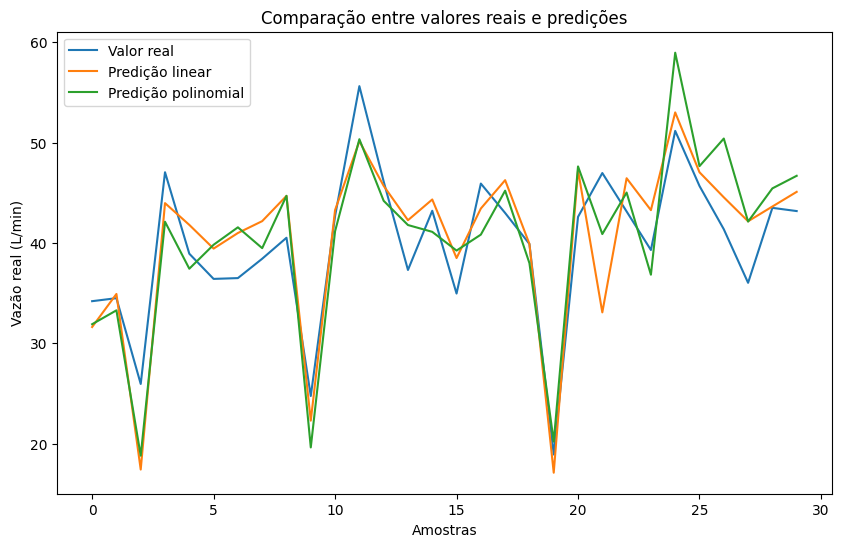

In [19]:
plt.figure(figsize=(10,6))
plt.plot(y_validacao.values[:30], label="Valor real")
plt.plot(pred_linear[:30], label="Predição linear")
plt.plot(pred_polinomial[:30], label="Predição polinomial")
plt.title("Comparação entre valores reais e predições")
plt.xlabel("Amostras")
plt.ylabel("Vazão real (L/min)")
plt.legend()
plt.show()

Explicação:

# **Gráfico de comparação entre valores reais e previsões dos modelos**

Foram comparados:

* valores reais da validação
* previsões da regressão linear
* previsões da regressão polinomial

---

# **Como interpretar o gráfico**

## Linha azul

Representa:

* os valores reais do sistema.

---

## Linha laranja

Representa:

* as previsões da regressão linear.

---

## Linha verde

Representa:

* as previsões da regressão polinomial.

---

# **O que o gráfico mostra**

As linhas dos modelos tentam acompanhar o comportamento da linha real.

Quanto mais próximas:

* melhor a previsão do modelo.

---

# **Resultado observado**

A regressão linear e a polinomial conseguiram acompanhar boa parte da tendência dos dados.

Porém:

* em alguns pontos ocorreram diferenças maiores entre previsão e valor real.

---

# **Ideia principal da imagem**

> os modelos estão tentando reproduzir o comportamento real dos dados para realizar previsões numéricas cada vez mais próximas da realidade operacional.


## 18. Comentário sobre regressão logística

Embora conste no plano do curso, a **regressão logística** não é usada para prever uma variável contínua.  
Ela é indicada quando a saída é categórica, por exemplo:

- falha / sem falha
- aprovado / reprovado
- normal / anormal

Na base desta aula, a coluna `falha_operacional` pode ser usada futuramente para discutir esse caso.

## 19. Conclusão técnica

Ao final desta aula, o aluno deve ser capaz de:

- organizar a base para modelagem;
- separar corretamente treino e validação;
- criar um pipeline de modelagem;
- treinar modelos de regressão;
- gerar predições;
- interpretar métricas;
- comparar modelos com base em evidências.

## 20. Evidência de aprendizagem esperada
- notebook funcional com os modelos implementados;
- tabela comparativa das métricas;
- análise escrita indicando qual modelo apresentou melhor ajuste.


### 1. Qual a função da etapa de treino?

> ensinar o modelo de Machine Learning a identificar padrões nos dados.

Nessa fase:

* o algoritmo analisa exemplos
* aprende relações entre entradas e respostas
* ajusta seus parâmetros para fazer previsões futuras.


### 2. Qual a função da etapa de validação?

> verificar se o modelo realmente aprendeu os padrões corretamente.

Nessa fase:

* o modelo recebe dados que não viu no treino
* suas previsões são testadas
* o desempenho é avaliado para medir precisão e capacidade de generalização.

### 3. Por que as métricas são importantes?

> elas medem a qualidade e o desempenho do modelo de Machine Learning.

Com as métricas é possível:

* verificar se o modelo está acertando
* comparar modelos diferentes
* identificar erros
* validar se o modelo é confiável para uso real.


### 4. Em que situação a regressão logística seria mais apropriada do que a regressão linear?

A regressão logística é mais apropriada quando o objetivo é:

> prever categorias ou probabilidades.

Exemplo:

* falha ou não falha
* aprovado ou reprovado
* fraude ou não fraude

Ela é usada em problemas de:

* classificação

---

Já a regressão linear é usada para prever:

* valores numéricos contínuos

Exemplo:

* temperatura
* pressão
* consumo energético

---
* Regressão logística → categorias
* Regressão linear → números contínuos